# Lab 06 — Implementation of Naïve Bayes Classifier Algorithms

| | |
|---|---|
| **Course** | Machine Learning Lab |
| **Name** | Talha Naveed |
| **Enrollment** | 01-131232-089 |
| **Lab** | 06 |

**Plan of this notebook**

1. **Main dataset — UCI Adult (Census Income).** It has both categorical and continuous features, real missing values, and a binary target (income `>50K` or not). All three Naïve Bayes variants are trained on it, each with the preprocessing that fits its assumptions, so they can be compared fairly on the same data.
2. **Each variant on its "natural" data** (as the task asks):
   - Bernoulli NB → SMS Spam Collection, binary word-presence features
   - Gaussian NB → Iris, continuous measurements
   - Multinomial NB → SMS Spam Collection, word-count features
3. **Comparison** of all three variants across all three datasets, with analysis.

Rule used everywhere: every preprocessing step (imputer, scaler, binning, vocabulary) is **fitted on the training set only** and then applied to the test set, so no information from the test set leaks into training.

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, StandardScaler, KBinsDiscretizer,
                                   LabelEncoder)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from sklearn.datasets import load_iris

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
RESULTS = {}   # every metric is stored here and saved to results.json at the end

## Helper: one evaluation function used for every model

It prints the four required metrics (accuracy, precision, recall, F1), the full classification report, and draws a confusion matrix.
For the comparison tables **macro-averaged** precision/recall/F1 are used: each class counts equally, which is the honest choice when classes are imbalanced (Adult is 76% / 24%, SMS is 87% / 13%).

In [2]:
def evaluate(name, y_true, y_pred, labels, dataset, fig_name=None, ax=None):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"=== {name} on {dataset} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}  (macro)")
    print(f"Recall   : {rec:.4f}  (macro)")
    print(f"F1-score : {f1:.4f}  (macro)\n")
    print(classification_report(y_true, y_pred, target_names=labels, digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(4.2, 3.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{name}\n{dataset}")
    if own_fig:
        plt.tight_layout()
        if fig_name: plt.savefig(f"figures/{fig_name}.png", dpi=200)
        plt.show()

    report = classification_report(y_true, y_pred, target_names=labels, output_dict=True, zero_division=0)
    RESULTS.setdefault(dataset, {})[name] = {
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1,
        "per_class": {k: report[k] for k in labels}, "confusion_matrix": cm.tolist()}
    return acc, prec, rec, f1

# Part 1 — Main dataset: UCI Adult (Census Income)

**Source:** UCI Machine Learning Repository (Becker & Kohavi, 1996). 48,842 records from the 1994 US Census.
**Goal:** predict whether a person earns more than \$50K a year.

| Type | Features |
|---|---|
| Continuous (6) | age, fnlwgt, education-num, capital-gain, capital-loss, hours-per-week |
| Categorical (8) | workclass, education, marital-status, occupation, relationship, race, sex, native-country |
| Target | income: `<=50K` / `>50K` |

In [3]:
cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
        "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
        "hours_per_week", "native_country", "income"]
adult = pd.read_csv("data/adult.csv", header=None, names=cols,
                    na_values="?", skipinitialspace=True)
print("Shape:", adult.shape)
adult.head()

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
cat_cols = ["workclass", "education", "marital_status", "occupation",
            "relationship", "race", "sex", "native_country"]

print("Missing values per column:")
missing = adult.isna().sum()
print(missing[missing > 0])
print(f"\nRows with at least one missing value: {adult.isna().any(axis=1).sum()} "
      f"({adult.isna().any(axis=1).mean()*100:.2f}%)")
print("\nClass balance:")
print(adult["income"].value_counts(normalize=True).round(4))
adult[num_cols].describe().round(2)

Missing values per column:
workclass         2799
occupation        2809
native_country     857
dtype: int64

Rows with at least one missing value: 3620 (7.41%)

Class balance:
income
<=50K    0.7607
>50K     0.2393
Name: proportion, dtype: float64


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.00,48842.00,48842.00,48842.00,48842.0,48842.00
mean,38.64,189664.13,10.08,1079.07,87.5,40.42
std,13.71,105604.03,2.57,7452.02,403.0,12.39
min,17.00,12285.00,1.00,0.00,0.0,1.00
25%,28.00,117550.50,9.00,0.00,0.0,40.00
50%,37.00,178144.50,10.00,0.00,0.0,40.00
75%,48.00,237642.00,12.00,0.00,0.0,45.00
max,90.00,1490400.00,16.00,99999.00,4356.0,99.00


### Handling missing data

Missing values are written as `?` in the raw file (read as `NaN` above). They appear only in three **categorical** columns: `workclass`, `occupation`, `native_country` (about 7.4% of rows).

Instead of deleting those rows (which would throw away data), each missing value is filled with the **most frequent category** of that column. The imputer is part of the pipeline, so the "most frequent" value is learned **from the training set only**.

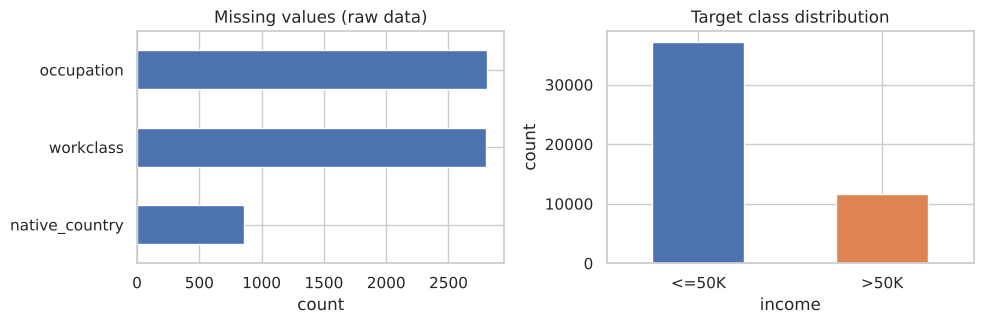

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
missing[missing > 0].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Missing values (raw data)"); axes[0].set_xlabel("count")
adult["income"].value_counts().plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452"], rot=0)
axes[1].set_title("Target class distribution"); axes[1].set_ylabel("count")
plt.tight_layout(); plt.savefig("figures/adult_eda.png", dpi=200); plt.show()

### Train / test split (80% / 20%)

`stratify=y` keeps the same 76/24 class ratio in both parts, so the test set is a fair sample.

In [6]:
X = adult.drop(columns="income")
y = (adult["income"] == ">50K").astype(int)          # 1 = >50K, 0 = <=50K
adult_labels = ["<=50K", ">50K"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train >50K ratio:", round(y_train.mean(), 4), "| Test >50K ratio:", round(y_test.mean(), 4))

Train: (39073, 14)  Test: (9769, 14)
Train >50K ratio: 0.2393 | Test >50K ratio: 0.2393


### Preprocessing for each variant

Each Naïve Bayes variant assumes a different shape for the data, so each gets its own preprocessing:

| Variant | What it assumes about each feature | Preprocessing applied |
|---|---|---|
| **Bernoulli NB** | 0/1 (present / absent) | Categorical → one-hot (already 0/1). Continuous → 1 if above the **training median**, else 0. For `capital_gain` / `capital_loss` the median is 0, so this becomes "has any capital gain/loss". |
| **Gaussian NB** | real numbers following a bell curve per class | Continuous → `StandardScaler`. Categorical → one-hot. (Scaling does not change GaussianNB's predictions, but the lab asks for it and it keeps the features comparable.) |
| **Multinomial NB** | non-negative counts | Continuous → split into 5 quantile bins, each bin one-hot. Categorical → one-hot. Each row then "counts" which bin/category it falls in. |

In [7]:
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

from sklearn.base import BaseEstimator, TransformerMixin

class MedianBinarizer(BaseEstimator, TransformerMixin):
    # Turns each continuous column into 0/1: 1 if value > that column's TRAINING median.
    def fit(self, X, y=None):
        self.medians_ = np.median(np.asarray(X, dtype=float), axis=0); return self
    def transform(self, X):
        return (np.asarray(X, dtype=float) > self.medians_).astype(float)

pre_bernoulli = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("bin",    MedianBinarizer())]), num_cols),
    ("cat", cat_pipe, cat_cols)])

pre_gaussian = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale",  StandardScaler())]), num_cols),
    ("cat", cat_pipe, cat_cols)])

pre_multinomial = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("bins",   KBinsDiscretizer(n_bins=5, encode="onehot-dense",
                                                  strategy="quantile", subsample=None))]),
     num_cols),
    ("cat", cat_pipe, cat_cols)])

models_adult = {
    "Bernoulli NB":   Pipeline([("pre", pre_bernoulli),   ("nb", BernoulliNB())]),
    "Gaussian NB":    Pipeline([("pre", pre_gaussian),    ("nb", GaussianNB())]),
    "Multinomial NB": Pipeline([("pre", pre_multinomial), ("nb", MultinomialNB())]),
}
for n, m in models_adult.items():
    m.fit(X_train, y_train)
    print(f"{n:15s} -> {m.named_steps['pre'].transform(X_train[:1]).shape[1]} features after preprocessing")

Bernoulli NB    -> 105 features after preprocessing


Gaussian NB     -> 105 features after preprocessing
Multinomial NB  -> 119 features after preprocessing


## (a) Bernoulli Naïve Bayes on Adult

=== Bernoulli NB on Adult ===
Accuracy : 0.7797
Precision: 0.7208  (macro)
Recall   : 0.7750  (macro)
F1-score : 0.7344  (macro)

              precision    recall  f1-score   support

       <=50K     0.9142    0.7840    0.8441      7431
        >50K     0.5274    0.7660    0.6247      2338

    accuracy                         0.7797      9769
   macro avg     0.7208    0.7750    0.7344      9769
weighted avg     0.8216    0.7797    0.7916      9769



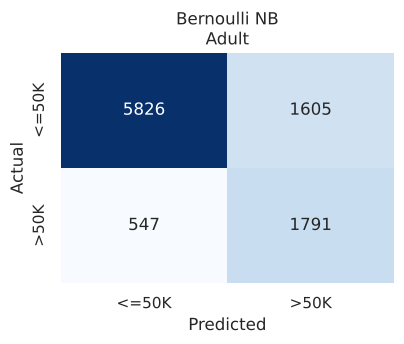

In [8]:
y_pred_b = models_adult["Bernoulli NB"].predict(X_test)
evaluate("Bernoulli NB", y_test, y_pred_b, adult_labels, "Adult", "cm_adult_bernoulli");

## (b) Gaussian Naïve Bayes on Adult

=== Gaussian NB on Adult ===
Accuracy : 0.5715
Precision: 0.6552  (macro)
Recall   : 0.6969  (macro)
F1-score : 0.5649  (macro)



              precision    recall  f1-score   support

       <=50K     0.9587    0.4563    0.6183      7431
        >50K     0.3517    0.9376    0.5116      2338

    accuracy                         0.5715      9769
   macro avg     0.6552    0.6969    0.5649      9769
weighted avg     0.8135    0.5715    0.5928      9769



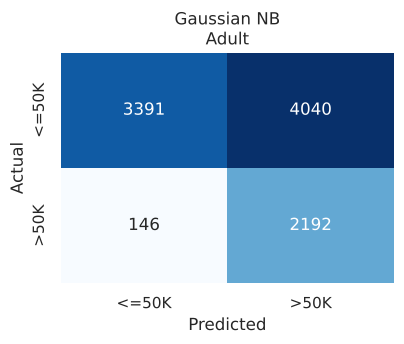

In [9]:
y_pred_g = models_adult["Gaussian NB"].predict(X_test)
evaluate("Gaussian NB", y_test, y_pred_g, adult_labels, "Adult", "cm_adult_gaussian");

Gaussian NB has a much lower accuracy here. Two features explain most of it: `capital_gain` and `capital_loss` are 0 for over 90% of people and very large for a few. That is nothing like a bell curve, so the Gaussian likelihood is badly wrong for them. The one-hot columns are also 0/1, not Gaussian. The check below shows this directly.

Share of zeros in training data:
capital_gain    0.9184
capital_loss    0.9536
dtype: float64

Skewness (0 = symmetric bell curve):


age                0.56
fnlwgt             1.42
education_num     -0.33
capital_gain      12.23
capital_loss       4.60
hours_per_week     0.23
dtype: float64


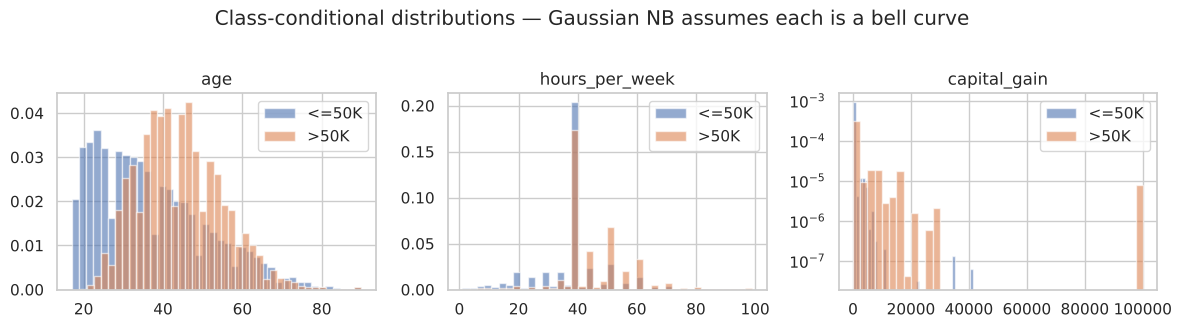

In [10]:
print("Share of zeros in training data:")
print((X_train[["capital_gain", "capital_loss"]] == 0).mean().round(4))
print("\nSkewness (0 = symmetric bell curve):")
print(X_train[num_cols].skew().round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, ["age", "hours_per_week", "capital_gain"]):
    for lab, col in [(0, "#4C72B0"), (1, "#DD8452")]:
        ax.hist(X_train.loc[y_train == lab, c], bins=40, alpha=0.6, density=True,
                color=col, label=adult_labels[lab])
    ax.set_title(c); ax.legend()
axes[2].set_yscale("log")
plt.suptitle("Class-conditional distributions — Gaussian NB assumes each is a bell curve", y=1.02)
plt.tight_layout(); plt.savefig("figures/adult_distributions.png", dpi=200, bbox_inches="tight"); plt.show()

## (c) Multinomial Naïve Bayes on Adult

=== Multinomial NB on Adult ===
Accuracy : 0.8092
Precision: 0.7452  (macro)
Recall   : 0.7868  (macro)
F1-score : 0.7599  (macro)

              precision    recall  f1-score   support

       <=50K     0.9115    0.8298    0.8687      7431
        >50K     0.5789    0.7438    0.6511      2338

    accuracy                         0.8092      9769
   macro avg     0.7452    0.7868    0.7599      9769
weighted avg     0.8319    0.8092    0.8166      9769



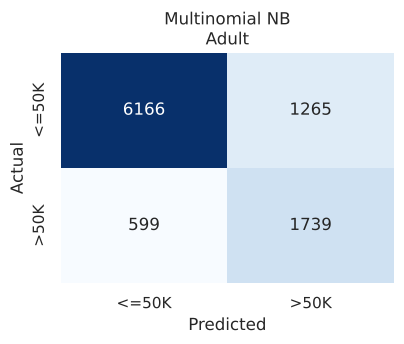

In [11]:
y_pred_m = models_adult["Multinomial NB"].predict(X_test)
evaluate("Multinomial NB", y_test, y_pred_m, adult_labels, "Adult", "cm_adult_multinomial");

### Robustness check: 5-fold stratified cross-validation on the training set

One 80/20 split can be lucky or unlucky. Cross-validation repeats the training on 5 different folds and reports mean ± standard deviation of macro-F1.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
RESULTS["Adult_CV"] = {}
for n, m in models_adult.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro")
    RESULTS["Adult_CV"][n] = {"mean": s.mean(), "std": s.std()}
    print(f"{n:15s} macro-F1 = {s.mean():.4f} ± {s.std():.4f}")

Bernoulli NB    macro-F1 = 0.7407 ± 0.0045


Gaussian NB     macro-F1 = 0.5632 ± 0.0161


Multinomial NB  macro-F1 = 0.7611 ± 0.0012


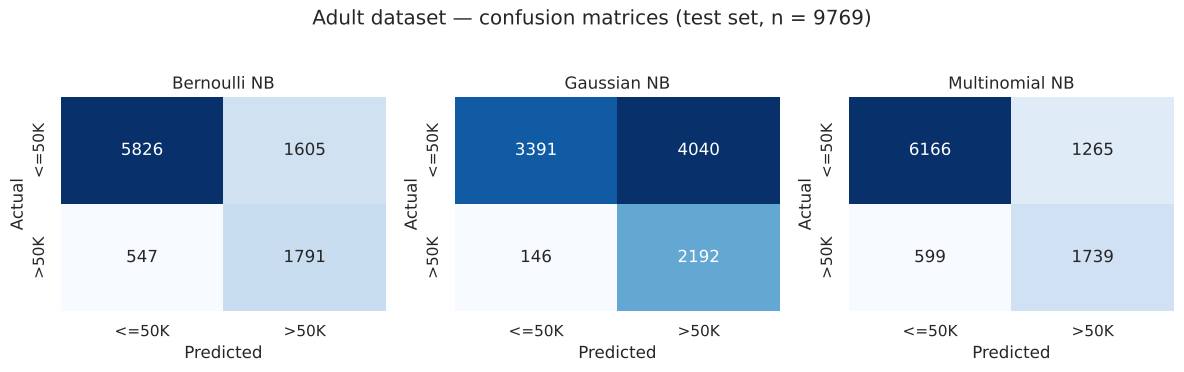

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (n, yp) in zip(axes, [("Bernoulli NB", y_pred_b), ("Gaussian NB", y_pred_g),
                              ("Multinomial NB", y_pred_m)]):
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=adult_labels, yticklabels=adult_labels, ax=ax)
    ax.set_title(n); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Adult dataset — confusion matrices (test set, n = %d)" % len(y_test), y=1.03)
plt.tight_layout(); plt.savefig("figures/cm_adult_all.png", dpi=200, bbox_inches="tight"); plt.show()

# Part 2 — Each variant on the data it was designed for

## SMS Spam Collection (for Bernoulli and Multinomial)

**Source:** UCI Machine Learning Repository (Almeida & Hidalgo, 2011). 5,572 SMS messages labelled `ham` (normal) or `spam`.
Text is turned into features with a **bag of words**: every word in the training vocabulary becomes one column.
- For **Bernoulli NB** the column is **1 if the word appears** in the message, else 0 (`binary=True`).
- For **Multinomial NB** the column is **how many times** the word appears.

In [14]:
sms = pd.read_csv("data/sms.tsv", sep="\t", header=None, names=["label", "message"])
print("Shape:", sms.shape, "| missing values:", sms.isna().sum().sum(),
      "| duplicate messages:", sms.duplicated().sum())
print(sms["label"].value_counts())
sms.head()

Shape: (5572, 2) | missing values: 0 | duplicate messages: 403
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


There are no missing values. Duplicate messages are removed so that the same text cannot appear in both train and test (that would inflate the scores).

In [15]:
sms = sms.drop_duplicates().reset_index(drop=True)
y_sms = (sms["label"] == "spam").astype(int)
sms_labels = ["ham", "spam"]
Xs_train_txt, Xs_test_txt, ys_train, ys_test = train_test_split(
    sms["message"], y_sms, test_size=0.20, random_state=RANDOM_STATE, stratify=y_sms)

vec_bin   = CountVectorizer(binary=True,  lowercase=True, stop_words="english")
vec_count = CountVectorizer(binary=False, lowercase=True, stop_words="english")
Xs_train_bin = vec_bin.fit_transform(Xs_train_txt);   Xs_test_bin = vec_bin.transform(Xs_test_txt)
Xs_train_cnt = vec_count.fit_transform(Xs_train_txt); Xs_test_cnt = vec_count.transform(Xs_test_txt)
print("After dedup:", sms.shape[0], "messages | train:", len(ys_train), "test:", len(ys_test))
print("Vocabulary size (learned from training messages only):", len(vec_bin.vocabulary_))

After dedup: 5169 messages | train: 4135 test: 1034
Vocabulary size (learned from training messages only): 7414


### (a) Bernoulli NB — spam detection with binary word-presence features

=== Bernoulli NB on SMS Spam ===
Accuracy : 0.9662
Precision: 0.9813  (macro)
Recall   : 0.8664  (macro)
F1-score : 0.9134  (macro)



              precision    recall  f1-score   support

         ham     0.9627    1.0000    0.9810       903
        spam     1.0000    0.7328    0.8458       131

    accuracy                         0.9662      1034
   macro avg     0.9813    0.8664    0.9134      1034
weighted avg     0.9674    0.9662    0.9639      1034



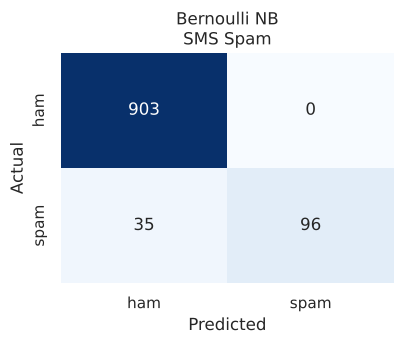

In [16]:
bnb_sms = BernoulliNB().fit(Xs_train_bin, ys_train)
evaluate("Bernoulli NB", ys_test, bnb_sms.predict(Xs_test_bin), sms_labels, "SMS Spam", "cm_sms_bernoulli");

### (c) Multinomial NB — spam detection with word-count features

=== Multinomial NB on SMS Spam ===
Accuracy : 0.9836
Precision: 0.9732  (macro)
Recall   : 0.9514  (macro)
F1-score : 0.9620  (macro)

              precision    recall  f1-score   support

         ham     0.9868    0.9945    0.9906       903
        spam     0.9597    0.9084    0.9333       131

    accuracy                         0.9836      1034
   macro avg     0.9732    0.9514    0.9620      1034
weighted avg     0.9834    0.9836    0.9834      1034



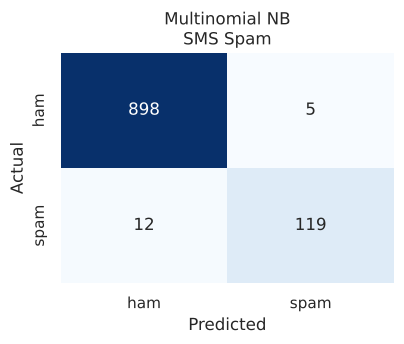

In [17]:
mnb_sms = MultinomialNB().fit(Xs_train_cnt, ys_train)
evaluate("Multinomial NB", ys_test, mnb_sms.predict(Xs_test_cnt), sms_labels, "SMS Spam", "cm_sms_multinomial");

For a complete comparison, Gaussian NB is also run on the same word counts (converted to a dense matrix). Word counts are mostly 0 with a few 1s and 2s — not a bell curve — so this is expected to be the weakest.

=== Gaussian NB on SMS Spam ===
Accuracy : 0.8781
Precision: 0.7473  (macro)
Recall   : 0.8878  (macro)
F1-score : 0.7890  (macro)

              precision    recall  f1-score   support

         ham     0.9838    0.8749    0.9261       903
        spam     0.5108    0.9008    0.6519       131

    accuracy                         0.8781      1034
   macro avg     0.7473    0.8878    0.7890      1034
weighted avg     0.9239    0.8781    0.8914      1034



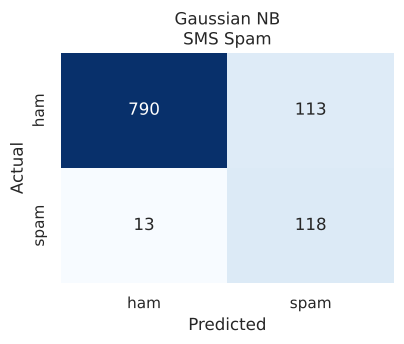

In [18]:
gnb_sms = GaussianNB().fit(Xs_train_cnt.toarray(), ys_train)
evaluate("Gaussian NB", ys_test, gnb_sms.predict(Xs_test_cnt.toarray()), sms_labels, "SMS Spam", "cm_sms_gaussian");

In [19]:
# Which words does Multinomial NB treat as the strongest spam signals?
log_ratio = mnb_sms.feature_log_prob_[1] - mnb_sms.feature_log_prob_[0]
vocab = np.array(vec_count.get_feature_names_out())
top = np.argsort(log_ratio)[::-1][:15]
print("Top 15 spam-indicating words:", ", ".join(vocab[top]))
RESULTS["SMS_top_spam_words"] = vocab[top].tolist()

Top 15 spam-indicating words: claim, prize, 150p, tone, www, 18, guaranteed, 500, 1000, cs, uk, awarded, 000, ringtone, 150ppm


## Iris (for Gaussian NB)

**Source:** UCI Machine Learning Repository (Fisher, 1936), bundled with scikit-learn. 150 flowers, 3 species (50 each), 4 continuous measurements in cm: sepal length, sepal width, petal length, petal width. No missing values.

In [20]:
iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
iris_labels = list(iris.target_names)
print("Shape:", Xi.shape, "| missing values:", Xi.isna().sum().sum())
print(yi.value_counts().sort_index().rename(index=dict(enumerate(iris_labels))))

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.20, random_state=RANDOM_STATE, stratify=yi)

scaler_i = StandardScaler().fit(Xi_train)       # fit on train only
Xi_train_s, Xi_test_s = scaler_i.transform(Xi_train), scaler_i.transform(Xi_test)
print("Train:", Xi_train.shape, " Test:", Xi_test.shape)

Shape: (150, 4) | missing values: 0
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Train: (120, 4)  Test: (30, 4)


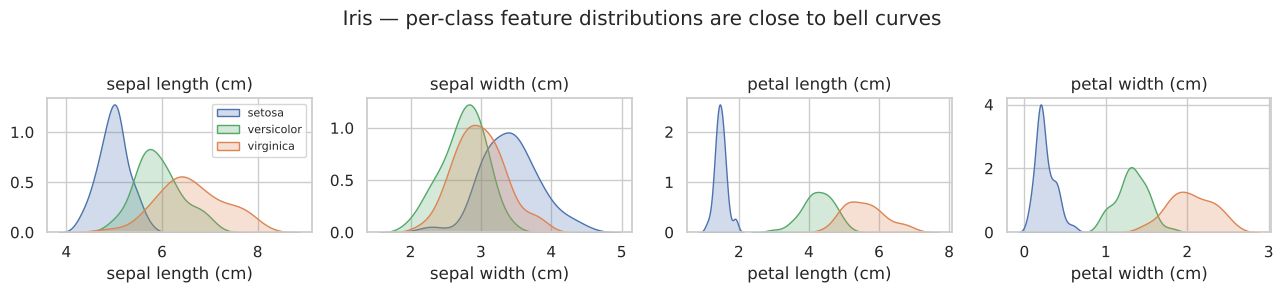

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, c in zip(axes, Xi.columns):
    for k, col in zip(range(3), ["#4C72B0", "#55A868", "#DD8452"]):
        sns.kdeplot(Xi_train.loc[yi_train == k, c], ax=ax, fill=True, color=col,
                    label=iris_labels[k], warn_singular=False)
    ax.set_title(c); ax.set_ylabel("")
axes[0].legend(fontsize=8)
plt.suptitle("Iris — per-class feature distributions are close to bell curves", y=1.04)
plt.tight_layout(); plt.savefig("figures/iris_distributions.png", dpi=200, bbox_inches="tight"); plt.show()

### (b) Gaussian NB — Iris

=== Gaussian NB on Iris ===
Accuracy : 0.9667
Precision: 0.9697  (macro)
Recall   : 0.9667  (macro)
F1-score : 0.9666  (macro)

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



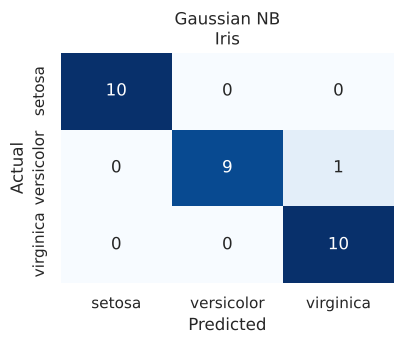

In [22]:
gnb_iris = GaussianNB().fit(Xi_train_s, yi_train)
evaluate("Gaussian NB", yi_test, gnb_iris.predict(Xi_test_s), iris_labels, "Iris", "cm_iris_gaussian");

For comparison, Bernoulli and Multinomial NB are also run on Iris:
- **Bernoulli:** each measurement → 1 if above its training median, else 0.
- **Multinomial:** uses the raw (unscaled, non-negative) centimetre values as if they were counts. MultinomialNB cannot take the negative values that StandardScaler produces.

=== Bernoulli NB on Iris ===
Accuracy : 0.7000
Precision: 0.6944  (macro)
Recall   : 0.7000  (macro)
F1-score : 0.6420  (macro)

              precision    recall  f1-score   support

      setosa     0.7500    0.9000    0.8182        10
  versicolor     0.6667    0.2000    0.3077        10
   virginica     0.6667    1.0000    0.8000        10

    accuracy                         0.7000        30
   macro avg     0.6944    0.7000    0.6420        30
weighted avg     0.6944    0.7000    0.6420        30



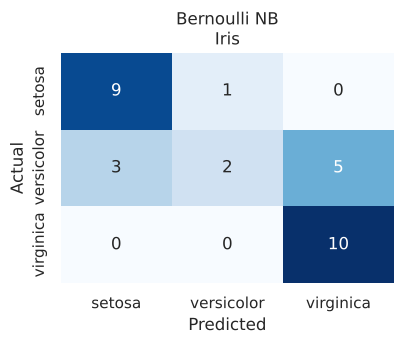

=== Multinomial NB on Iris ===
Accuracy : 1.0000
Precision: 1.0000  (macro)
Recall   : 1.0000  (macro)
F1-score : 1.0000  (macro)

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000        10
   virginica     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



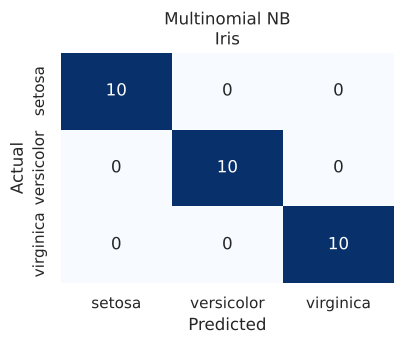

In [23]:
mb = MedianBinarizer().fit(Xi_train)
bnb_iris = BernoulliNB().fit(mb.transform(Xi_train), yi_train)
evaluate("Bernoulli NB", yi_test, bnb_iris.predict(mb.transform(Xi_test)), iris_labels, "Iris", "cm_iris_bernoulli");

mnb_iris = MultinomialNB().fit(Xi_train, yi_train)
evaluate("Multinomial NB", yi_test, mnb_iris.predict(Xi_test), iris_labels, "Iris", "cm_iris_multinomial");

### Is the Iris result trustworthy? Repeated cross-validation

The Iris test set has only **30 flowers**, so one wrong prediction changes accuracy by 3.3 percentage points. A single split is too small to rank Gaussian against Multinomial. Below, each variant is trained and tested 50 times (5-fold CV repeated 10 times with different shuffles) on the full 150 flowers.

In [24]:
from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
iris_models = {
    "Bernoulli NB":   Pipeline([("bin", MedianBinarizer()), ("nb", BernoulliNB())]),
    "Gaussian NB":    Pipeline([("scale", StandardScaler()), ("nb", GaussianNB())]),
    "Multinomial NB": MultinomialNB(),
}
RESULTS["Iris_CV"] = {}
for n, m in iris_models.items():
    s = cross_val_score(m, Xi, yi, cv=rcv, scoring="f1_macro")
    RESULTS["Iris_CV"][n] = {"mean": s.mean(), "std": s.std()}
    print(f"{n:15s} macro-F1 = {s.mean():.4f} ± {s.std():.4f}   (50 runs)")

Bernoulli NB    macro-F1 = 0.6691 ± 0.0796   (50 runs)


Gaussian NB     macro-F1 = 0.9545 ± 0.0346   (50 runs)


Multinomial NB  macro-F1 = 0.9545 ± 0.0326   (50 runs)


# Part 3 — Comparison of the three variants

In [25]:
rows = []
for ds in ["Adult", "SMS Spam", "Iris"]:
    for m in ["Bernoulli NB", "Gaussian NB", "Multinomial NB"]:
        r = RESULTS[ds][m]
        rows.append([ds, m, r["accuracy"], r["precision"], r["recall"], r["f1"]])
comp = pd.DataFrame(rows, columns=["Dataset", "Classifier", "Accuracy",
                                   "Precision (macro)", "Recall (macro)", "F1 (macro)"])
comp.round(4)

,Dataset,Classifier,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Adult,Bernoulli NB,0.7797,0.7208,0.7750,0.7344
1,Adult,Gaussian NB,0.5715,0.6552,0.6969,0.5649
2,Adult,Multinomial NB,0.8092,0.7452,0.7868,0.7599
3,SMS Spam,Bernoulli NB,0.9662,0.9813,0.8664,0.9134
4,SMS Spam,Gaussian NB,0.8781,0.7473,0.8878,0.7890
5,SMS Spam,Multinomial NB,0.9836,0.9732,0.9514,0.9620
6,Iris,Bernoulli NB,0.7000,0.6944,0.7000,0.6420
7,Iris,Gaussian NB,0.9667,0.9697,0.9667,0.9666
8,Iris,Multinomial NB,1.0000,1.0000,1.0000,1.0000


In [26]:
best = comp.loc[comp.groupby("Dataset", sort=False)["F1 (macro)"].idxmax(), ["Dataset", "Classifier", "F1 (macro)"]]
print("Best variant per dataset (by macro-F1):")
print(best.to_string(index=False))

Best variant per dataset (by macro-F1):
 Dataset     Classifier  F1 (macro)
   Adult Multinomial NB    0.759881
SMS Spam Multinomial NB    0.961978
    Iris Multinomial NB    1.000000


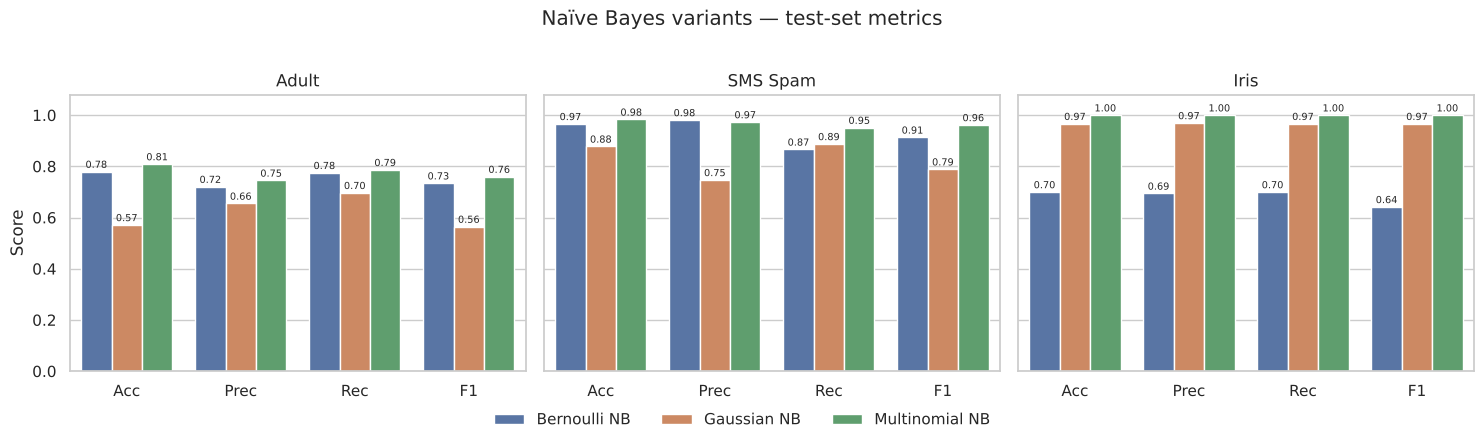

In [27]:
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
palette = {"Bernoulli NB": "#4C72B0", "Gaussian NB": "#DD8452", "Multinomial NB": "#55A868"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, ds in zip(axes, ["Adult", "SMS Spam", "Iris"]):
    d = comp[comp.Dataset == ds].melt(id_vars="Classifier", value_vars=metrics,
                                      var_name="Metric", value_name="Score")
    sns.barplot(data=d, x="Metric", y="Score", hue="Classifier", palette=palette, ax=ax)
    ax.set_title(ds); ax.set_xlabel(""); ax.set_ylim(0, 1.08)
    ax.set_xticklabels(["Acc", "Prec", "Rec", "F1"])
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)
    ax.get_legend().remove()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06), frameon=False)
plt.suptitle("Naïve Bayes variants — test-set metrics", y=1.02)
plt.tight_layout(); plt.savefig("figures/comparison.png", dpi=200, bbox_inches="tight"); plt.show()

In [28]:
# Per-class recall on Adult: the minority class (>50K) is where the variants differ most
for m in ["Bernoulli NB", "Gaussian NB", "Multinomial NB"]:
    pc = RESULTS["Adult"][m]["per_class"]
    print(f"{m:15s}  recall <=50K = {pc['<=50K']['recall']:.4f}   recall >50K = {pc['>50K']['recall']:.4f}"
          f"   precision >50K = {pc['>50K']['precision']:.4f}")

Bernoulli NB     recall <=50K = 0.7840   recall >50K = 0.7660   precision >50K = 0.5274
Gaussian NB      recall <=50K = 0.4563   recall >50K = 0.9376   precision >50K = 0.3517
Multinomial NB   recall <=50K = 0.8298   recall >50K = 0.7438   precision >50K = 0.5789


In [29]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
comp.to_csv("comparison.csv", index=False)
print("Saved results.json and comparison.csv")

Saved results.json and comparison.csv


# Analysis and conclusion

**Adult — the main mixed-feature dataset.** Multinomial NB is best (accuracy 80.9%, macro-F1 0.760), Bernoulli NB is close (78.0%, 0.734) and Gaussian NB is far behind (57.2%, 0.565). Cross-validation gives the same order with small spread, so the ranking is reliable. After one-hot encoding, 99 of the 105 features are 0/1 indicators — exactly what Bernoulli and Multinomial expect. Gaussian NB must model those indicators and the very skewed `capital_gain` (92% zeros, skewness 12.2) as bell curves. That wrong assumption makes it predict `>50K` far too often: it catches 93.8% of high earners but only 35.2% of its `>50K` predictions are correct, and it gets just 45.6% of `<=50K` people right. Multinomial beats Bernoulli because 5 quantile bins keep more detail than a single above/below-median split.

**SMS Spam — text.** Multinomial NB is best (98.4% accuracy, macro-F1 0.962). Word counts are exactly the data it models, which is why it is the standard baseline for text classification. Bernoulli NB never flags a normal message as spam (spam precision 1.00) but misses 27% of spam (spam recall 0.73), because it also counts every *absent* vocabulary word as evidence, and short messages leave most of the 7,414 words absent. Gaussian NB catches spam (recall 0.90) but half its spam alarms are false (precision 0.51), because sparse counts are not bell-shaped.

**Iris — continuous.** On the single 30-flower test split Multinomial scored 100% and Gaussian 96.7%, but that gap is one flower. Over 50 cross-validation runs the two are tied (macro-F1 ≈ 0.955 each), so the honest conclusion is that both work well and the single split cannot separate them. Gaussian NB is the principled choice here, because each measurement is close to a bell curve within each species (see the distribution plot). Multinomial does well only because petal sizes differ so much between species; treating centimetres as "counts" is not a sound model in general. Bernoulli is clearly worst (≈ 0.67) because a median split throws away most of the information — e.g. it cannot tell versicolor (middle-sized petals) from the other two.

**Overall:** no single variant wins everywhere; the best choice follows the shape of the features. Bernoulli suits binary present/absent data, Multinomial suits counts and one-hot/discretised data, and Gaussian suits continuous, roughly normal measurements. For the chosen mixed dataset (Adult), **Multinomial NB with discretised continuous features** is the best variant.